# Delivery Route Optimisation Using ILP and SA

IT5082 Optimization Methods

**Problem:**  Capacitated Vehicle Routing Problem (CVRP) <br>
**Exact method:** ILP <br>
**Heuristic:**  Simulated Annealing (SA) <br>
**Data:**  CVRPLIB benchmarks and the Amazon Last Mile 2021 routes<br>
**M L I U Meegahawala (MS26903538)  / M T M Ibjas (MS25942248)**

## Setup
Install the packages from requirements.txt

In [1]:
import itertools, json, math, os, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, linprog, LinearConstraint, Bounds
from scipy.sparse import coo_matrix
import vrplib

# numba speedup the  SA decoder
try:
    from numba import njit
except ImportError:
    def njit(*args, **kwargs):
        return args[0] if args and callable(args[0]) else (lambda f: f)


SEED = 42
CONFIG = dict(
    exact_time_limit = 120,    # seconds per ILP solve
    exact_max_n      = 45,     # largest instance we try with the ILP
    n_seeds          = 10,     # SA runs per instance
    sa_iters_per_n   = 1500,   # SA iterations = this x number of customers
)

def sa_budget(inst):
    """SA iterations for an instance. The same for every seed, so the comparison is fair."""
    return CONFIG["sa_iters_per_n"] * inst["n"]


# Folders: raw input files, saved instances, figures. Created if they do not exist yet.
RAW, INST, FIG = Path("data/raw"), Path("data/instances"), Path("results/figures")
for p in (RAW, INST, FIG, Path("results")):
    p.mkdir(parents=True, exist_ok=True)

# Plot style for every figure: default size, light grid, no top and right border lines
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

# Fixed random seeds, so a re-run gives the same numbers
random.seed(SEED)
np.random.seed(SEED)

print("Config:", CONFIG)

Config: {'exact_time_limit': 120, 'exact_max_n': 45, 'n_seeds': 10, 'sa_iters_per_n': 1500}


## Load the CVRPLIB instances
CVRPLIB gives a proven optimal cost for each instance. We use it to check our ILP and to measure how far SA is from the best answer. <br>The `.vrp` files are added to `data/raw/.

In [2]:
CVRPLIB_OPTIMA = {                      # proven optimal costs, published on CVRPLIB
    "P-n16-k8": 450, "E-n22-k4": 375, "A-n32-k5": 784,
    "A-n33-k5": 661, "A-n60-k9": 1354, "A-n80-k10": 1763,
}

def find_instances():
    """Return the CVRPLIB instances that have a .vrp file in data/raw/."""
    found = [n for n in CVRPLIB_OPTIMA if (RAW / f"{n}.vrp").exists()]
    print(f"found {len(found)} instance files in {RAW}/")
    return found

## Convert to common instance format
ILP and SA read the same input. instance is a plain Python dict.
<br>Distances use CVRPLIB's straight-line distance rounded to the nearest integer.(euclidean_matrix)
<br>The depot is node `0`.

In [3]:
def euclidean_matrix(coords):
    """Distance between every pair of points, rounded to the nearest integer (CVRPLIB rule)."""
    pts = np.asarray(coords, dtype=float)
    d = np.sqrt(((pts[:, None, :] - pts[None, :, :]) ** 2).sum(-1))   # straight-line distances
    return np.rint(d).astype(int)


def parse_cvrplib(path, name=None):
    """Read one .vrp file and return it in to a dict."""
    raw = vrplib.read_instance(str(path))
    name = name or Path(path).stem
    demand = np.asarray(raw["demand"], dtype=int)
    coords = np.asarray(raw["node_coord"], dtype=float)
    return {
        "name": name, "source": "CVRPLIB", "n": len(demand) - 1,     # n = customers without the depot
        "coords": coords.tolist(), "demand": demand.tolist(),
        "capacity": int(raw["capacity"]), "depot": 0,
        "vehicles": int(name.rsplit("-k", 1)[1]),                    # fleet size is in the name A-n32-k5 -> 5
        "dist": euclidean_matrix(coords).tolist(),
        "cost_unit": "distance units", "known_opt": CVRPLIB_OPTIMA.get(name),
    }

def save_instance(inst):
    """Save an instance as JSON in data/instances/."""
    p = INST / f"{inst['name']}.json"
    p.write_text(json.dumps(inst))
    return p

def validate_instance(inst):
    """Valiidate the instances, so a bad instance can be removed"""
    d, D = np.asarray(inst["demand"]), np.asarray(inst["dist"])
    nm = inst["name"]
    assert inst["depot"] == 0, f"{nm}: depot must be node 0"
    assert D.shape == (len(d), len(d)), f"{nm}: matrix shape {D.shape} != {len(d)}"
    assert d[0] == 0, f"{nm}: depot has non-zero demand"
    assert d.max() <= inst["capacity"], f"{nm}: a single demand exceeds capacity"
    assert (np.diag(D) == 0).all() and (D >= 0).all(), f"{nm}: bad cost matrix"
    need = math.ceil(d.sum() / inst["capacity"])                     # fewest vehicles that could carry all demand
    assert need <= inst["vehicles"], f"{nm}: needs {need} vehicles but fleet is {inst['vehicles']}"
    return True


def instance_summary(instances):
    """summary table for report"""
    rows = []
    for i in instances:
        d = np.asarray(i["demand"])
        rows.append({"name": i["name"], "source": i["source"], "n": i["n"], "capacity": i["capacity"],
                     "total_demand": int(d.sum()), "vehicles": i["vehicles"],
                     "min_vehicles": math.ceil(d.sum() / i["capacity"]),
                     "tightness": round(d.sum() / (i["vehicles"] * i["capacity"]), 3),   # 1.0 = fleet is completely full
                     "known_opt": i["known_opt"], "cost_unit": i["cost_unit"]})
    return pd.DataFrame(rows).sort_values(["source", "n"]).reset_index(drop=True)


## Amazon Last Mile data`
Real delivery routes from the Amazon Last Mile Routing Challenge 2021.

<b>We use small subset from one station, saved in data/raw/amazon_subset.json

In [4]:
AMZ_SUBSET = RAW / "amazon_subset.json"      # small file cut from the full Amazon data (see tools/extract_amazon_subset.py for extraction script)
AMAZON = json.loads(AMZ_SUBSET.read_text())
print(f"Amazon subset: station {AMAZON['station']}, {len(AMAZON['route_data'])} routes")

Amazon subset: station DLA3, 12 routes


## Build CVRP instances from one Amazon route
- **Depot:** delivery station.
- **Customers:** fixed random sample of the stops
- **Demand:** package volume at the stop, in litres.
- **Cost:** real travel time in seconds. It is asymmetric (A to B is not B to A).
- **Capacity:** The real van carries the whole route, so we use several smaller vans instead. Capacity = total demand / (vehicles × fill).

In [5]:
def amazon_route_to_instance(A, rid, n_stops, fleet=4, fill=0.85, seed=SEED):
    """Turn one Amazon route into a CVRP instance with n_stops customers."""
    rd, pk, tt = A["route_data"][rid], A["package_data"][rid], A["travel_times"][rid]
    stops = rd["stops"]

    # Depot = the station. Customers = delivery stops that have packages.
    depot_id = next(s for s, v in stops.items() if v.get("type") == "Station")
    customers = [s for s, v in stops.items() if v.get("type") == "Dropoff" and s in pk]

    # Fixed-seed shuffle, so smaller instances are always inside the bigger ones.
    random.Random(seed).shuffle(customers)
    ids = [depot_id] + customers[:n_stops]                      # node 0 = depot

    # Demand of a stop = total volume of its packages, in litres (cm3 / 1000), rounded up, at least 1.
    def volume_l(stop):
        return sum(p["dimensions"]["depth_cm"] * p["dimensions"]["height_cm"] * p["dimensions"]["width_cm"]
                   for p in pk[stop].values()) / 1000.0
    demand = [0] + [max(1, math.ceil(volume_l(s))) for s in ids[1:]]

    # Cost = real travel time in seconds. It is not symmetric: D[a][b] can differ from D[b][a].
    D = np.array([[0 if a == b else round(tt[a][b]) for b in ids] for a in ids])

    # Capacity is our assumption: total demand spread over the fleet, with vans about `fill` (85%) full.
    # max(...) makes sure the biggest single stop still fits in one van.
    capacity = max(math.ceil(sum(demand) / (fleet * fill)), max(demand))

    return {"name": f"AMZ-{rid[-6:]}-n{n_stops}", "source": "Amazon", "n": n_stops,
            "coords": [[stops[s]["lng"], stops[s]["lat"]] for s in ids],
            "demand": demand, "capacity": capacity, "depot": 0, "vehicles": fleet,
            "dist": D.tolist(), "cost_unit": "seconds", "known_opt": None, "route_id": rid}


def build_amazon_instances(A, sizes=(10, 15, 20, 30, 50, 80), fleet_for=lambda n: max(2, math.ceil(n / 8))):
    """Build one instance per size, all from the same route (the one with the most deliveries)."""
    n_drop = lambda r: sum(v.get("type") == "Dropoff" for v in A["route_data"][r]["stops"].values())
    rid = max(A["route_data"], key=n_drop)
    return [amazon_route_to_instance(A, rid, n, fleet=fleet_for(n)) for n in sizes if n <= n_drop(rid)]

## Load, validate and sumamrise
Load all instances and check each one with `validate_instance`. `instance_summary` table summarises every instance.

In [6]:
# 1) CVRPLIB instances: read every .vrp file found in data/raw/
instances = [parse_cvrplib(RAW / f"{nm}.vrp", nm) for nm in find_instances()]

# 2) Amazon instances: build them from the saved subset
instances += build_amazon_instances(AMAZON)

# 3) Check each instance, then save it as JSON in data/instances/
for inst in instances:
    validate_instance(inst)
    save_instance(inst)

by_name = {i["name"]: i for i in instances}      # quick lookup by name
SMOKE = by_name["P-n16-k8"]                      # small instance used for quick demos and checks

reg = instance_summary(instances)           # summary table (Table 1 in the report)
print(f"{len(instances)} instances validated and saved to {INST}/")
reg

found 6 instance files in data/raw/
12 instances validated and saved to data/instances/


,name,source,n,capacity,total_demand,vehicles,min_vehicles,tightness,known_opt,cost_unit
0,AMZ-c6a02b-n10,Amazon,10,127,215,2,2,0.846,NaN,seconds
1,AMZ-c6a02b-n15,Amazon,15,149,252,2,2,0.846,NaN,seconds
2,AMZ-c6a02b-n20,Amazon,20,146,370,3,3,0.845,NaN,seconds
3,AMZ-c6a02b-n30,Amazon,30,187,633,4,4,0.846,NaN,seconds
4,AMZ-c6a02b-n50,Amazon,50,161,957,7,6,0.849,NaN,seconds
5,AMZ-c6a02b-n80,Amazon,80,180,1529,10,9,0.849,NaN,seconds
6,P-n16-k8,CVRPLIB,15,35,246,8,8,0.879,450.0,distance units
7,E-n22-k4,CVRPLIB,21,6000,22500,4,4,0.938,375.0,distance units
8,A-n32-k5,CVRPLIB,31,100,410,5,5,0.820,784.0,distance units
9,A-n33-k5,CVRPLIB,32,100,446,5,5,0.892,661.0,distance units


## Instance analysis
Before running any method we look at the instances to see **what makes them hard**. This is the optimisation equivalent of exploratory data analysis: we check where the stops are, how big the demands are against vehicle capacity, whether the cost matrix is symmetric, and how fast the search space grows.

### Where the stops are
Three CVRPLIB instances and one Amazon instance. Marker size shows demand; the black square is the depot. CVRPLIB customers are spread out, while the Amazon stops sit in a tight cluster with the depot far away.

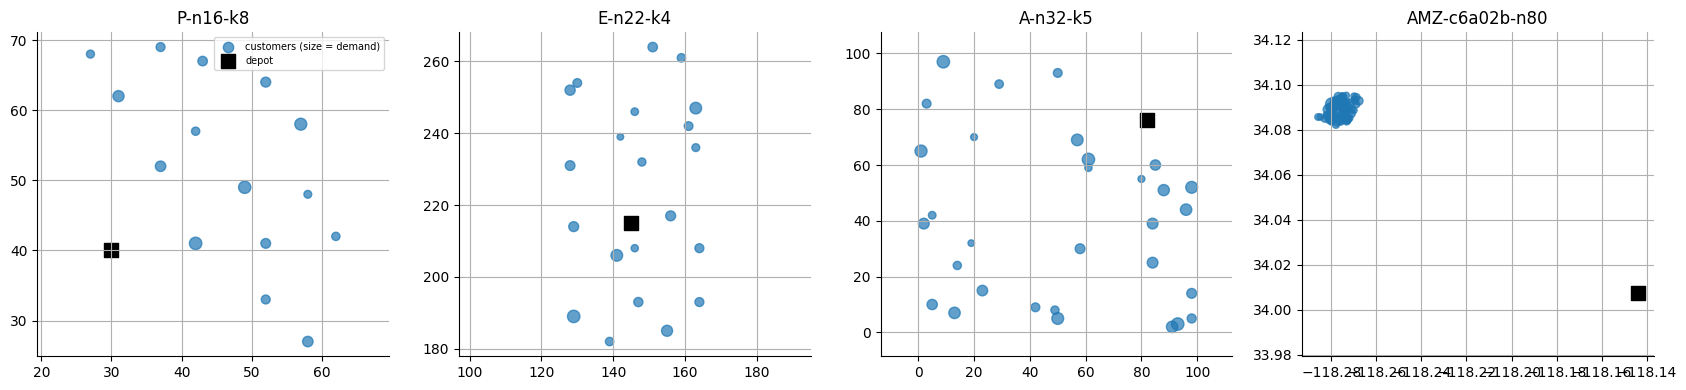

In [7]:
def plot_instance(inst, ax=None, title=None):
    ax = ax or plt.gca()
    xy, d = np.asarray(inst["coords"]), np.asarray(inst["demand"])
    ax.scatter(xy[1:, 0], xy[1:, 1], s=20 + 6 * d[1:] / max(1, d[1:].max()) * 10, alpha=.7, label="customers (size = demand)")
    ax.scatter(*xy[0], marker="s", s=90, c="k", label="depot")
    ax.set_title(title or inst["name"]); ax.set_aspect("equal", "datalim")

pick = [i for i in instances if i["name"] in ("P-n16-k8", "E-n22-k4", "A-n32-k5")] or instances[:3]
amz = [i for i in instances if i["source"] == "Amazon"]
pick = (pick + amz[-1:])[:4]
fig, axs = plt.subplots(1, len(pick), figsize=(4.2 * len(pick), 4))
for a, i in zip(np.atleast_1d(axs), pick): plot_instance(i, a)
np.atleast_1d(axs)[0].legend(fontsize=7, loc="best")
plt.tight_layout(); plt.savefig(FIG / "2_1_instances.png", dpi=150); plt.show()

### Demand distribution and capacity tightness
Left: each customer's demand as a share of vehicle capacity. Right: capacity tightness (total demand / (K x Q)); a value close to 1 means little slack, so the instance is usually harder.

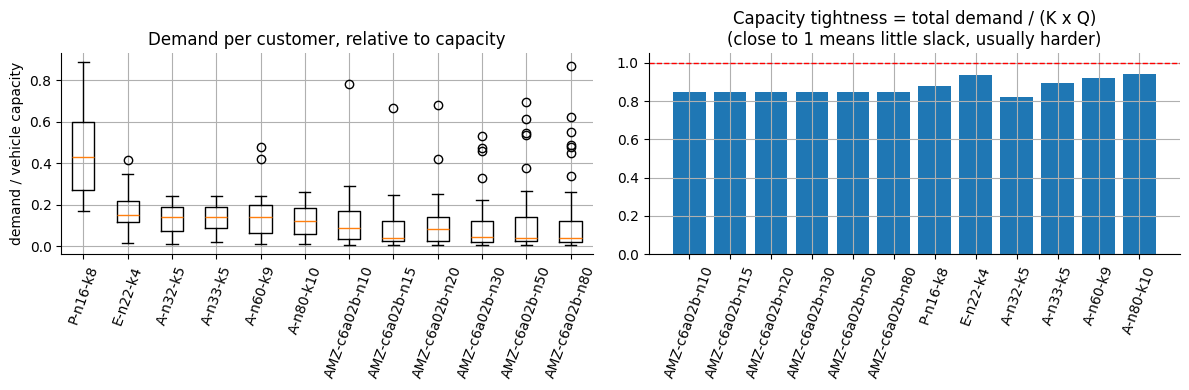

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
data = [np.asarray(i["demand"][1:]) / i["capacity"] for i in instances]
axs[0].boxplot(data); axs[0].set_xticks(range(1, len(instances) + 1)); axs[0].set_xticklabels([i["name"] for i in instances])
axs[0].set_ylabel("demand / vehicle capacity"); axs[0].set_title("Demand per customer, relative to capacity")
axs[0].tick_params(axis="x", rotation=70)
t = reg.set_index("name")["tightness"]
axs[1].bar(range(len(t)), t.values); axs[1].set_xticks(range(len(t))); axs[1].set_xticklabels(t.index, rotation=70)
axs[1].axhline(1, color="r", ls="--", lw=1); axs[1].set_ylim(0, 1.05)
axs[1].set_title("Capacity tightness = total demand / (K x Q)\n(close to 1 means little slack, usually harder)")
plt.tight_layout(); plt.savefig(FIG / "2_2_demand_tightness.png", dpi=150); plt.show()

### Cost matrix: symmetric or not?
CVRPLIB distances are symmetric (Euclidean). The Amazon travel times are **not** (one-way streets, turns, traffic). We measure the share of node pairs whose two directions differ by more than 10%, which justifies a **directed** formulation that uses the full asymmetric matrix.

In [9]:
rows = []
for i in instances:
    D = np.asarray(i["dist"], float); iu = np.triu_indices(len(D), 1)
    a, b = D[iu], D.T[iu]
    rel = np.abs(a - b) / np.maximum(1, (a + b) / 2)
    rows.append({"instance": i["name"], "pairs": len(a), "share_asymmetric_>10%": round(float((rel > .10).mean()), 3),
                 "mean_rel_diff": round(float(rel.mean()), 3)})
sym = pd.DataFrame(rows); sym

,instance,pairs,share_asymmetric_>10%,mean_rel_diff
0,P-n16-k8,120,0.000,0.000
1,E-n22-k4,231,0.000,0.000
2,A-n32-k5,496,0.000,0.000
3,A-n33-k5,528,0.000,0.000
4,A-n60-k9,1770,0.000,0.000
5,A-n80-k10,3160,0.000,0.000
6,AMZ-c6a02b-n10,55,0.309,0.101
7,AMZ-c6a02b-n15,120,0.267,0.087
8,AMZ-c6a02b-n20,210,0.295,0.088
9,AMZ-c6a02b-n30,465,0.327,0.093


### Why we need a heuristic: the size of the problem
For `n` customers the ILP has about `n(n+1)` binary arc variables, but the number of visiting orders is `n!`. The ILP model stays small while the search space explodes, so exact solvers rely on bounding and pruning and a fast heuristic becomes attractive as `n` grows.**

,n customers,binary arc variables n(n+1),visiting orders n!
0,5,30,1.20e+02
1,8,72,4.03e+04
2,10,110,3.63e+06
3,15,240,1.31e+12
4,20,420,2.43e+18
5,30,930,2.65e+32
6,50,2550,3.04e+64
7,80,6480,7.16e+118
8,100,10100,9.33e+157


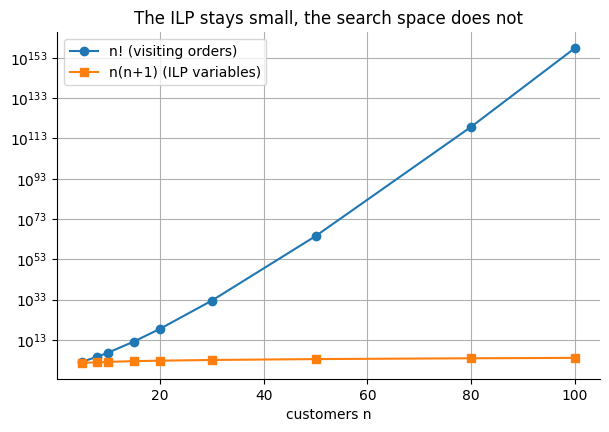

In [10]:
ns = np.array([5, 8, 10, 15, 20, 30, 50, 80, 100])
growth = pd.DataFrame({"n customers": ns, "binary arc variables n(n+1)": ns * (ns + 1),
                       "visiting orders n!": [f"{math.factorial(int(n)):.2e}" for n in ns]})
display(growth)
fig, ax = plt.subplots(); ax.semilogy(ns, [math.factorial(int(n)) for n in ns], "o-", label="n! (visiting orders)")
ax.semilogy(ns, ns * (ns + 1), "s-", label="n(n+1) (ILP variables)"); ax.set_xlabel("customers n"); ax.legend()
ax.set_title("The ILP stays small, the search space does not"); plt.savefig(FIG / "2_5_growth.png", dpi=150); plt.show()

# Exact method: ILP with branch and bound

**Problem:** one depot, n customers, K identical vehicles with capacity Q. Visit every customer once and keep each route within capacity. Minimise the total travel cost.

**Variables:**
- x(i,j) is binary. It is 1 if a vehicle drives from customer i to customer j, otherwise 0.
- u(i) is the load delivered so far when the vehicle leaves customer i.

**Objective:** minimise the total cost of all arcs used.

**Constraints:**
1. Leave each customer once.
2. Enter each customer once.
3. Exactly K vehicles leave the depot and return to it.
4. Load builds up along a route (MTZ): if a vehicle drives from i to j, the load at j is at least the load at i plus the demand of j.
5. Capacity: the load at i is at least its own demand and at most Q.

Constraints 4 and 5 keep every route within capacity. They also stop loops that skip the depot.

**LP relaxation:** if we drop the rule that x must be binary, we get an LP. Its answer is a lower bound on the best cost.

CVRP is NP-hard, so exact solving gets very slow as n grows.

In [11]:
def build_milp(inst):
    """Build the MTZ model as matrices for scipy's milp:
       min c.z   s.t.   lb <= A z <= ub,   with bounds and integrality.
       z = [x_ij for every arc | u_i for every customer]"""
    D, q, Q = np.asarray(inst["dist"], float), np.asarray(inst["demand"]), inst["capacity"]
    K = inst["vehicles"]
    N = len(q)                                   # nodes; node 0 is the depot
    C = list(range(1, N))                        # customers

    # Column numbers: arc variables x_ij first, then load variables u_i
    arcs = [(i, j) for i in range(N) for j in range(N) if i != j]
    x = {a: k for k, a in enumerate(arcs)}
    nA = len(arcs)
    u = {i: nA + k for k, i in enumerate(C)}

    # Objective: total arc cost (u_i has no cost)
    c = np.r_[[D[i, j] for i, j in arcs], np.zeros(len(C))]

    # Each constraint is one row:  low <= sum(value * variable) <= high
    rows, lo, hi = [], [], []
    def add(entries, low, high):
        rows.append(entries); lo.append(low); hi.append(high)

    for i in C:                                  # (1) leave each customer once
        add([(x[i, j], 1) for j in range(N) if j != i], 1, 1)
    for j in C:                                  # (2) enter each customer once
        add([(x[i, j], 1) for i in range(N) if i != j], 1, 1)
    add([(x[0, j], 1) for j in C], K, K)         # (3) exactly K vehicles leave the depot
    add([(x[i, 0], 1) for i in C], K, K)         #     and exactly K return
    for i in C:                                  # (4) MTZ: u_j - u_i - Q*x_ij >= q_j - Q
        for j in C:
            if i != j:
                add([(u[j], 1), (u[i], -1), (x[i, j], -Q)], q[j] - Q, np.inf)

    # Turn the rows into one sparse matrix A
    A = coo_matrix(([v for e in rows for _, v in e],
                    ([k for k, e in enumerate(rows) for _ in e],
                     [col for e in rows for col, _ in e])),
                   shape=(len(rows), nA + len(C))).tocsr()

    integrality = np.r_[np.ones(nA), np.zeros(len(C))]   # x binary, u continuous
    bounds = Bounds(np.r_[np.zeros(nA), q[C]],           # 0 <= x <= 1,  (5) q_i <= u_i <= Q
                    np.r_[np.ones(nA), np.full(len(C), Q)])
    return dict(c=c, A=A, lb=np.array(lo, float), ub=np.array(hi, float),
                integrality=integrality, bounds=bounds, arcs=arcs, nA=nA)


# Size check on the smallest benchmark instance
m = build_milp(SMOKE)
n_bin = int(m["integrality"].sum())
print(f"model size: {m['A'].shape[0]} constraints x {m['A'].shape[1]} variables "
      f"({n_bin} binary, {m['A'].shape[1] - n_bin} continuous)")

model size: 242 constraints x 255 variables (240 binary, 15 continuous)


## Routes and the solution check

After each ILP solve, we read the routes from the solvers x values and check them. Every customer must be visited once, no route should be over capacity, and the cost must match.

In [12]:
def route_cost(route, D):
    """Cost of depot -> route -> depot."""
    path = [0] + list(route) + [0]
    return float(sum(D[a][b] for a, b in zip(path, path[1:])))


def extract_routes(zvec, arcs, nA):
    """Read the routes from the solver's x values (the arcs with x = 1)."""
    x = np.rint(zvec[:nA]).astype(int)
    used = [a for a, val in zip(arcs, x) if val == 1]
    next_stop = {i: j for i, j in used if i != 0}      # which node follows customer i
    routes = []
    for first in [j for i, j in used if i == 0]:       # each arc leaving the depot starts a route
        route, node = [], first
        while node != 0:                               # follow the arcs until we are back at the depot
            route.append(node)
            node = next_stop[node]
            assert len(route) <= len(next_stop) + 1, "malformed solution (loop)"
        routes.append(route)
    return routes


def check_solution(routes, inst, reported_cost=None, tol=1e-6):
    """Check a solution from scratch. Returns feasible or not, the real cost and the problems found."""
    D, q, Q, K = np.asarray(inst["dist"]), np.asarray(inst["demand"]), inst["capacity"], inst["vehicles"]
    routes = [r for r in routes if r]                  # ignore empty routes
    problems = []

    if sorted(c for r in routes for c in r) != list(range(1, len(q))):
        problems.append("a customer is missing or visited twice")
    if any(q[r].sum() > Q for r in routes):
        problems.append("a route exceeds capacity")
    if len(routes) > K:
        problems.append(f"uses {len(routes)} vehicles, fleet is {K}")

    cost = sum(route_cost(r, D) for r in routes)       # cost recomputed from the distance matrix
    if reported_cost is not None and abs(cost - reported_cost) > 1e-4 + tol * abs(cost):
        problems.append(f"cost mismatch {cost} vs reported {reported_cost}")

    return {"feasible": not problems, "cost": cost, "vehicles": len(routes), "problems": "; ".join(problems)}

## Solve with HiGHS

We give each solve a time limit. It ends in one of three ways:
- **Proven optimal:** the best solution is the true optimum (gap = 0).
- **Feasible only:** time ran out, but we have a solution. The solver also gives a bound, so the gap shows how far the solution can be from the optimum.
- **No solution:** time ran out before any solution was found.

In [13]:
# Names for the status codes that scipy's milp returns
STATUS = {0: "ProvenOptimal", 1: "TimeLimit", 2: "Infeasible", 3: "Unbounded", 4: "Other"}


def solve_exact(inst, time_limit=None):
    """Solve one instance with the ILP and return the result as a dict."""
    time_limit = time_limit or CONFIG["exact_time_limit"]
    m = build_milp(inst)

    t0 = time.perf_counter()
    res = milp(m["c"], constraints=LinearConstraint(m["A"], m["lb"], m["ub"]),
               integrality=m["integrality"], bounds=m["bounds"],
               options={"time_limit": float(time_limit), "disp": False})

    out = {"instance": inst["name"], "n": inst["n"], "method": "ILP (HiGHS)",
           "runtime_s": round(time.perf_counter() - t0, 2),
           "status": STATUS.get(res.status, str(res.status)),
           "n_vars": m["A"].shape[1], "n_cons": m["A"].shape[0],
           "objective": None, "best_bound": getattr(res, "mip_dual_bound", None), "gap_%": None,
           "nodes": getattr(res, "mip_node_count", None), "routes": None, "feasible": False}

    if res.x is not None:                                   # the solver found a solution
        out["objective"] = float(res.fun)
        out["routes"] = extract_routes(res.x, m["arcs"], m["nA"])
        out["feasible"] = check_solution(out["routes"], inst, out["objective"])["feasible"]
        gap = getattr(res, "mip_gap", None)
        out["gap_%"] = round(100 * gap, 2) if gap is not None and np.isfinite(gap) else None
    elif res.status == 1:                                   # time ran out with no solution
        out["status"] = "NoSolutionInTime"
    return out


EXACT_CACHE = {}                    # instance name -> result, so no instance is solved twice

def get_exact(inst, **kw):
    """Return the ILP result for an instance, solving it only the first time."""
    if inst["name"] not in EXACT_CACHE:
        EXACT_CACHE[inst["name"]] = solve_exact(inst, **kw)
    return EXACT_CACHE[inst["name"]]


# Test on the smallest instance
smoke_res = solve_exact(SMOKE, time_limit=60)
print({k: v for k, v in smoke_res.items() if k != "routes"})
print("routes:", smoke_res["routes"])

{'instance': 'P-n16-k8', 'n': 15, 'method': 'ILP (HiGHS)', 'runtime_s': 1.12, 'status': 'ProvenOptimal', 'n_vars': 255, 'n_cons': 242, 'objective': 449.9999999999999, 'best_bound': 449.9999999999999, 'gap_%': 0.0, 'nodes': 847, 'feasible': True}
routes: [[1], [2], [3, 9, 5], [6], [11, 4], [13, 8], [14, 7], [15, 12, 10]]


## LP relaxation and the integrality gap  `[Owner: Ishara]`

We drop the "x must be binary" rule and solve the model as an LP with `linprog` (Labs 3 and 4). The result is a **lower bound**: LP value ≤ best integer solution

In [14]:
def lp_relaxation(inst):
    """Optimal value of the model when x may be fractional. It is a lower bound on the true optimum."""
    m = build_milp(inst)
    A, lb = m["A"], m["lb"]

    # linprog wants equality and inequality rows separately
    eq = np.isclose(lb, m["ub"])                     # rows with lb = ub are equalities
    A_eq, b_eq = A[eq], lb[eq]                       # A z = b
    A_ub, b_ub = -A[~eq], -lb[~eq]                   # A z >= lb  becomes  -A z <= -lb

    bounds = list(zip(m["bounds"].lb, m["bounds"].ub))
    res = linprog(m["c"], A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
    return float(res.fun)


# Integrality gap = how far the LP bound is below the known optimum
rows = []
for inst in instances:
    if inst["source"] == "CVRPLIB" and inst["known_opt"]:
        lp = lp_relaxation(inst)
        rows.append({"instance": inst["name"], "LP relaxation": round(lp, 1), "optimum": inst["known_opt"],
                     "integrality gap %": round(100 * (inst["known_opt"] - lp) / inst["known_opt"], 1)})
lp_table = pd.DataFrame(rows)
lp_table

,instance,LP relaxation,optimum,integrality gap %
0,P-n16-k8,396.3,450,11.9
1,E-n22-k4,278.9,375,25.6
2,A-n32-k5,546.2,784,30.3
3,A-n33-k5,439.7,661,33.5
4,A-n60-k9,641.7,1354,52.6
5,A-n80-k10,1052.7,1763,40.3


The gap is large because the MTZ relaxation is weak. A weak bound means branch and bound has to explore many nodes. That is why the ILP stops proving optimality as the instance grows.

## Check against the published optima
If the model is right, the ILP matches each published optimum. If time runs out, it can be above the optimum but never below it.

In [15]:
# Run the ILP on the CVRPLIB instances small enough for the exact method
val_rows = []
val_set = [i for i in instances if i["source"] == "CVRPLIB" and i["n"] <= CONFIG["exact_max_n"]]
for inst in val_set:
    r = get_exact(inst)
    val_rows.append({k: r[k] for k in ("instance", "n", "status", "objective", "best_bound", "gap_%", "nodes", "runtime_s", "feasible")}
                    | {"published_opt": inst["known_opt"]})
    print(f"  {inst['name']:<10} {r['status']:<14} obj={r['objective']} published={inst['known_opt']} t={r['runtime_s']}s")

validation = pd.DataFrame(val_rows)

# Two checks against the published optimum
validation["matches_published"] = validation["objective"].round(0) == validation["published_opt"]
validation["beats_published (must be False)"] = validation["objective"] < validation["published_opt"] - 0.5   # would mean a bug
validation

  P-n16-k8   ProvenOptimal  obj=449.9999999999999 published=450 t=1.12s
  E-n22-k4   TimeLimit      obj=374.99999999999994 published=375 t=120.01s
  A-n32-k5   TimeLimit      obj=842.0 published=784 t=120.01s
  A-n33-k5   TimeLimit      obj=725.0 published=661 t=120.01s


,instance,n,status,objective,best_bound,gap_%,nodes,runtime_s,feasible,published_opt,matches_published,beats_published (must be False)
0,P-n16-k8,15,ProvenOptimal,450.0,450.0,0.00,847,1.12,True,450,True,False
1,E-n22-k4,21,TimeLimit,375.0,354.0,5.60,100237,120.01,True,375,True,False
2,A-n32-k5,31,TimeLimit,842.0,613.0,27.20,45514,120.01,True,784,False,False
3,A-n33-k5,32,TimeLimit,725.0,508.0,29.93,32740,120.01,True,661,False,False


## Plotting routes

A helper to draw a solution. First use: the ILP routes for the small instance.

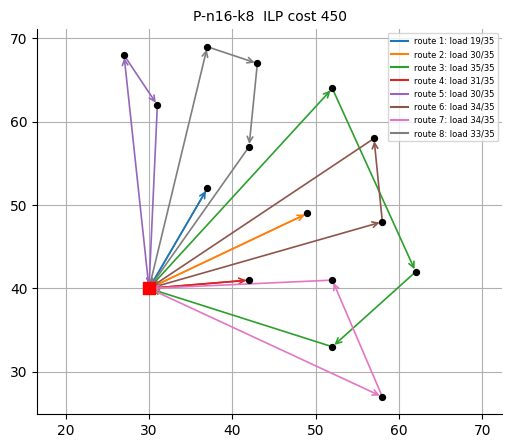

In [16]:
def plot_routes(routes, inst, ax=None, title=None):
    """Draw the routes of a solution: depot = red square, one colour per route."""
    ax = ax or plt.gca()
    xy, demand = np.asarray(inst["coords"]), np.asarray(inst["demand"])
    colors = plt.get_cmap("tab10")

    for k, route in enumerate([r for r in routes if r]):
        path = [0] + list(route) + [0]
        for a, b in zip(path, path[1:]):                    # one arrow per leg of the route
            ax.annotate("", xy=xy[b], xytext=xy[a], arrowprops=dict(arrowstyle="->", color=colors(k % 10), lw=1.2))
        ax.plot([], [], color=colors(k % 10),               # empty line, only to create the legend entry
                label=f"route {k+1}: load {int(demand[list(route)].sum())}/{inst['capacity']}")

    ax.scatter(xy[1:, 0], xy[1:, 1], s=18, c="k", zorder=3)     # customers
    ax.scatter(*xy[0], marker="s", s=80, c="r", zorder=4)       # depot
    ax.set_title(title or inst["name"], fontsize=10)
    ax.set_aspect("equal", "datalim")
    ax.legend(fontsize=6, loc="best")


# Draw the ILP routes for the small instance and save the figure
plt.figure(figsize=(6, 5))
plot_routes(smoke_res["routes"], SMOKE, title=f"{SMOKE['name']}  ILP cost {smoke_res['objective']:.0f}")
plt.savefig(FIG / "4_6_ilp_routes.png", dpi=150)
plt.show()

## How big can the ILP become
We run the ILP on every instance up to `exact_max_n` customers, with a fixed time limit, and **keep the timeouts**. If the solver finds a good solution but cannot prove it is optimal, that is still a result.

In [17]:
# Run the ILP on every instance up to exact_max_n customers (timeouts are kept)
exact_rows = []
exact_set = [i for i in instances if i["n"] <= CONFIG["exact_max_n"]]
for inst in exact_set:
    r = get_exact(inst)                               # instances already solved above come from the cache
    exact_rows.append(dict(r) | {"source": inst["source"], "known_opt": inst["known_opt"]})
    print(f"  {inst['name']}: {r['status']}, {r['runtime_s']}s")

exact_df = pd.DataFrame(exact_rows)
exact_df[["instance", "n", "status", "objective", "best_bound", "gap_%", "nodes", "runtime_s"]]

  P-n16-k8: ProvenOptimal, 1.12s
  E-n22-k4: TimeLimit, 120.01s
  A-n32-k5: TimeLimit, 120.01s
  A-n33-k5: TimeLimit, 120.01s
  AMZ-c6a02b-n10: ProvenOptimal, 0.05s
  AMZ-c6a02b-n15: ProvenOptimal, 0.83s
  AMZ-c6a02b-n20: ProvenOptimal, 34.08s
  AMZ-c6a02b-n30: TimeLimit, 120.01s


,instance,n,status,objective,best_bound,gap_%,nodes,runtime_s
0,P-n16-k8,15,ProvenOptimal,450.0,450.0,0.00,847,1.12
1,E-n22-k4,21,TimeLimit,375.0,354.0,5.60,100237,120.01
2,A-n32-k5,31,TimeLimit,842.0,613.0,27.20,45514,120.01
3,A-n33-k5,32,TimeLimit,725.0,508.0,29.93,32740,120.01
4,AMZ-c6a02b-n10,10,ProvenOptimal,7177.0,7177.0,0.00,1,0.05
5,AMZ-c6a02b-n15,15,ProvenOptimal,7545.0,7545.0,0.00,85,0.83
6,AMZ-c6a02b-n20,20,ProvenOptimal,10733.0,10732.0,0.01,25146,34.08
7,AMZ-c6a02b-n30,30,TimeLimit,14290.0,14156.0,0.94,50461,120.01


# Heuristic: Simulated Annealing

## Encoding and decoder
- A solution is an **order of the customers** (a "giant tour").
- A **decoder** cuts the order into routes. It picks the cheapest cut points that keep every route within capacity (dynamic programming, the "split" of Prins 2004).
- So **every order is a feasible CVRP solution**, and the SA moves never need repair.
- The one thing the encoding cannot guarantee is the fleet size `K`. The decoder may use a few extra vehicles, each with a penalty `r` (a static penalty `F = f + r·v`). `check_solution` flags any final solution that uses more than `K`.

In [20]:
QUICK = bool(int(os.environ.get("OM_QUICK", "0")))   # OM_QUICK=1 runs a fast, reduced tuning

@njit(cache=True)
def _split(perm, D, q, Q, K, Kmax, r):
    """Best way to cut a giant tour into at most Kmax capacity-feasible routes (dynamic programming).
    Fitness = total route cost + r * (number of routes beyond K).
    Returns (fitness, number of routes used, table needed to rebuild the routes)."""
    n = perm.shape[0]
    INF = 1e18
    chain = np.zeros(n)                                   # chain[t] = cost of driving perm[0] -> ... -> perm[t] in order
    for t in range(1, n):
        chain[t] = chain[t - 1] + D[perm[t - 1], perm[t]]
    pref = np.zeros(n + 1)                                # pref[t] = total demand of perm[0..t-1]
    for t in range(n):
        pref[t + 1] = pref[t] + q[perm[t]]
    dp = np.full((Kmax + 1, n + 1), INF)                  # dp[k, j] = cheapest cost to serve the first j customers with k routes
    dp[0, 0] = 0.0
    pred = np.zeros((Kmax + 1, n + 1), dtype=np.int64)    # where the last route started
    for k in range(1, Kmax + 1):
        for j in range(1, n + 1):
            best = INF
            bi = -1
            for i in range(j - 1, -1, -1):                # try: the last route serves perm[i..j-1]
                if pref[j] - pref[i] > Q:                 # over capacity, and it only gets worse
                    break
                if dp[k - 1, i] < INF:
                    c = dp[k - 1, i] + D[0, perm[i]] + (chain[j - 1] - chain[i]) + D[perm[j - 1], 0]
                    if c < best:
                        best = c
                        bi = i
            dp[k, j] = best
            pred[k, j] = bi
    bestfit = INF                                         # pick the number of routes with the lowest fitness
    kb = 1
    for k in range(1, Kmax + 1):
        if dp[k, n] < INF:
            fit = dp[k, n] + (r * (k - K) if k > K else 0.0)
            if fit < bestfit:
                bestfit = fit
                kb = k
    return bestfit, kb, pred


class Problem:
    """Wraps one instance for the heuristic. Customers are 1..n, the depot is 0."""
    def __init__(self, inst):
        self.D = np.asarray(inst["dist"], dtype=np.float64)
        self.q = np.asarray(inst["demand"], dtype=np.int64)
        self.Q, self.K, self.n = int(inst["capacity"]), int(inst["vehicles"]), len(self.q) - 1
        self.Kmax = self.K + max(2, math.ceil(0.25 * self.K))   # allow a few extra vehicles, at a penalty
        self.r = 10.0 * float(self.D[0, 1:].mean())             # penalty per extra vehicle (much bigger than a typical route)

    def fitness(self, perm):
        """Cost of the best split of this customer order (plus the penalty)."""
        return _split(np.asarray(perm, dtype=np.int64), self.D, self.q, self.Q, self.K, self.Kmax, self.r)[0]

    def decode(self, perm):
        """Turn a customer order into a list of routes."""
        perm = np.asarray(perm, dtype=np.int64)
        _, k, pred = _split(perm, self.D, self.q, self.Q, self.K, self.Kmax, self.r)
        routes, j = [], len(perm)
        while k > 0:                                    # walk back through the table, last route first
            i = pred[k, j]
            routes.append([int(c) for c in perm[i:j]])
            j, k = i, k - 1
        return routes[::-1]


problem = Problem(SMOKE)
demo = np.random.permutation(np.arange(1, problem.n + 1))
print("random order ->", problem.decode(demo), "| fitness", round(problem.fitness(demo), 1))

random order -> [[10, 12], [1], [14], [6], [9, 3], [2], [15, 5], [8, 11], [13, 4], [7]] | fitness 1121.7


## Brute-force check
**Brute force** tries every order of the customers. It is exact but needs `n!` evaluations, so it only works on a tiny instance. We use it as a third, independent check that the ILP is correct.

In [21]:
def sub_instance(inst, customers, K):
    """A smaller instance made of the depot and the chosen customers."""
    keep = [0] + list(customers)
    return {**inst, "name": f"{inst['name']}-sub{len(customers)}", "n": len(customers),
            "coords": [inst["coords"][i] for i in keep], "demand": [inst["demand"][i] for i in keep],
            "dist": np.asarray(inst["dist"])[np.ix_(keep, keep)].tolist(), "vehicles": K, "known_opt": None}


def brute_force(inst):
    """Try every customer order. Returns the cheapest cost, its routes and how many orders were tried."""
    P = Problem(inst)
    assert P.n <= 9, "brute force is factorial: keep n <= 9"
    best, best_perm, tried = 1e18, None, 0
    for perm in itertools.permutations(range(1, P.n + 1)):
        tried += 1
        f = P.fitness(perm)
        if f < best:
            best, best_perm = f, perm
    return best, P.decode(best_perm), tried


customers = list(range(1, 9))                           # the first 8 customers of P-n16-k8
fleet = math.ceil(sum(SMOKE["demand"][c] for c in customers) / SMOKE["capacity"])    # fewest vehicles by volume
while True:                                             # packing may need more vehicles, so grow the fleet until it works
    tiny = sub_instance(SMOKE, customers, fleet)
    t0 = time.perf_counter()
    bf_cost, bf_routes, bf_tried = brute_force(tiny)
    t_bf = time.perf_counter() - t0
    if len(bf_routes) <= fleet:
        break
    fleet += 1

ilp_tiny = solve_exact(tiny, time_limit=30)
print(f"tiny instance: {tiny['n']} customers, {tiny['vehicles']} vehicles")
print(f"brute force : cost {bf_cost:.0f}  ({bf_tried:,} orders, {t_bf:.1f}s)  {bf_routes}")
print(f"ILP         : cost {ilp_tiny['objective']:.0f}  ({ilp_tiny['status']}, {ilp_tiny['runtime_s']}s)")
print("ILP and brute force agree:", abs(bf_cost - ilp_tiny["objective"]) < 1e-6)

tiny instance: 8 customers, 6 vehicles
brute force : cost 293  (40,320 orders, 0.1s)  [[1, 3], [2], [4], [5, 7], [6], [8]]
ILP         : cost 293  (ProvenOptimal, 0.02s)
ILP and brute force agree: True


## Simulated Annealing
- **State:** a giant tour. **Neighbours:** swap two customers, move one customer elsewhere, or reverse a segment.
- **Acceptance:** a better move is always accepted. A worse move is accepted with probability `exp(-ΔE / T)`.
- **Cooling:** `T ← α·T`. `α` is set so that `T` falls from `T0` to `T_end` over the run.

In [22]:
def run_sa(inst, iters, t0_frac=0.05, t_end_ratio=1e-3, seed=0, log_every=200):
    """Simulated annealing on the giant tour.
    t0_frac: start temperature as a fraction of the first cost.
    t_end_ratio: final temperature divided by the start temperature."""
    P = Problem(inst)
    rnd = random.Random(seed)
    n = P.n
    cur = list(range(1, n + 1))
    rnd.shuffle(cur)                                       # random start
    E = P.fitness(cur)
    best, bestE = cur[:], E
    T = t0_frac * E                                        # start temperature
    alpha = t_end_ratio ** (1.0 / iters)                   # cooling factor: after `iters` steps T = T0 * t_end_ratio
    history, accepted = [], 0
    t_start = time.perf_counter()
    for it in range(iters):
        new = cur[:]
        u = rnd.random()
        i, j = sorted(rnd.sample(range(n), 2))
        if u < 0.4:                                        # swap two customers
            new[i], new[j] = new[j], new[i]
        elif u < 0.7:                                      # move one customer to another place
            new.insert(j, new.pop(i))
        else:                                              # reverse a segment (2-opt move)
            new[i:j + 1] = new[i:j + 1][::-1]
        E_new = P.fitness(new)
        dE = E_new - E                                     # minimisation: positive means worse
        if dE <= 0 or rnd.random() < math.exp(-dE / T):    # accept better moves, and worse ones with probability exp(-dE/T)
            cur, E = new, E_new
            accepted += 1
            if E < bestE:
                best, bestE = cur[:], E
        T *= alpha                                         # cool down
        if it % log_every == 0:
            history.append((it, E, bestE, T))
    return {"cost": float(bestE), "routes": P.decode(best), "runtime_s": time.perf_counter() - t_start,
            "history": pd.DataFrame(history, columns=["iter", "current", "best", "T"]),
            "accept_rate": accepted / iters}


r_sa = run_sa(SMOKE, sa_budget(SMOKE), seed=1)
print("SA on", SMOKE["name"], "-> cost", round(r_sa["cost"], 1), "| published", SMOKE["known_opt"],
      f"| {r_sa['runtime_s']:.1f}s | accept rate {r_sa['accept_rate']:.2f}")

SA on P-n16-k8 -> cost 450.0 | published 450 | 0.1s | accept rate 0.21


## Parameter tuning
We compare settings on **one mid-size instance** (E-n22-k4) with several seeds and the **same iteration budget** for every setting. The best mean setting is then frozen for all later runs, which keeps the comparison fair.

In [25]:
tune_inst = by_name["E-n22-k4"]
iters = sa_budget(tune_inst)
tune_seeds = range(2 if QUICK else 4)
t0_values = [0.02, 0.1] if QUICK else [0.01, 0.05, 0.2]           # start temperature / first cost
tend_values = [1e-2, 1e-3] if QUICK else [1e-2, 1e-3, 1e-4]       # final temperature / start temperature

rows = []
for t0f in t0_values:
    for te in tend_values:
        costs = [run_sa(tune_inst, iters, t0_frac=t0f, t_end_ratio=te, seed=s)["cost"] for s in tune_seeds]
        rows.append({"T0 / initial cost": t0f, "T_end / T0": te, "mean_cost": np.mean(costs), "best_cost": min(costs)})
        print(f"  T0={t0f}, T_end/T0={te}: mean cost {np.mean(costs):.2f}")

sa_tune = pd.DataFrame(rows).sort_values("mean_cost").reset_index(drop=True)
SA_PARAMS = {"t0_frac": float(sa_tune.loc[0, "T0 / initial cost"]), "t_end_ratio": float(sa_tune.loc[0, "T_end / T0"])}
print(f"SA tuning on {tune_inst['name']} ({iters} iterations per run)")
display(sa_tune)
print("frozen SA params:", SA_PARAMS)

  T0=0.01, T_end/T0=0.01: mean cost 376.75
  T0=0.01, T_end/T0=0.001: mean cost 378.50
  T0=0.01, T_end/T0=0.0001: mean cost 376.75
  T0=0.05, T_end/T0=0.01: mean cost 376.75
  T0=0.05, T_end/T0=0.001: mean cost 376.75
  T0=0.05, T_end/T0=0.0001: mean cost 379.75
  T0=0.2, T_end/T0=0.01: mean cost 378.00
  T0=0.2, T_end/T0=0.001: mean cost 378.50
  T0=0.2, T_end/T0=0.0001: mean cost 378.00
SA tuning on E-n22-k4 (31500 iterations per run)


,T0 / initial cost,T_end / T0,mean_cost,best_cost
0,0.01,0.0100,376.75,375.0
1,0.01,0.0001,376.75,375.0
2,0.05,0.0100,376.75,375.0
3,0.05,0.0010,376.75,375.0
4,0.20,0.0100,378.00,375.0
5,0.20,0.0001,378.00,375.0
6,0.01,0.0010,378.50,375.0
7,0.20,0.0010,378.50,375.0
8,0.05,0.0001,379.75,375.0


frozen SA params: {'t0_frac': 0.01, 't_end_ratio': 0.01}


  T0=0.05, T_end/T0=0.01: mean cost 376.75


  T0=0.05, T_end/T0=0.001: mean cost 376.75


...

  T0=0.2, T_end/T0=0.01: mean cost 378.00


  T0=0.2, T_end/T0=0.001: mean cost 378.50


  T0=0.2, T_end/T0=0.0001: mean cost 378.00
SA tuning on E-n22-k4 (31500 iterations per run)


,T0 / initial cost,T_end / T0,mean_cost,best_cost
0,0.01,0.0100,376.75,375.0
1,0.01,0.0001,376.75,375.0
2,0.05,0.0100,376.75,375.0
3,0.05,0.0010,376.75,375.0
4,0.20,0.0100,378.00,375.0
5,0.20,0.0001,378.00,375.0
6,0.01,0.0010,378.50,375.0
7,0.20,0.0010,378.50,375.0
8,0.05,0.0001,379.75,375.0


frozen SA params: {'t0_frac': 0.01, 't_end_ratio': 0.01}


## SA convergence
The blue line is the current cost. It goes up and down because worse moves are sometimes accepted. The orange line is the best so far, and the red line is the temperature.

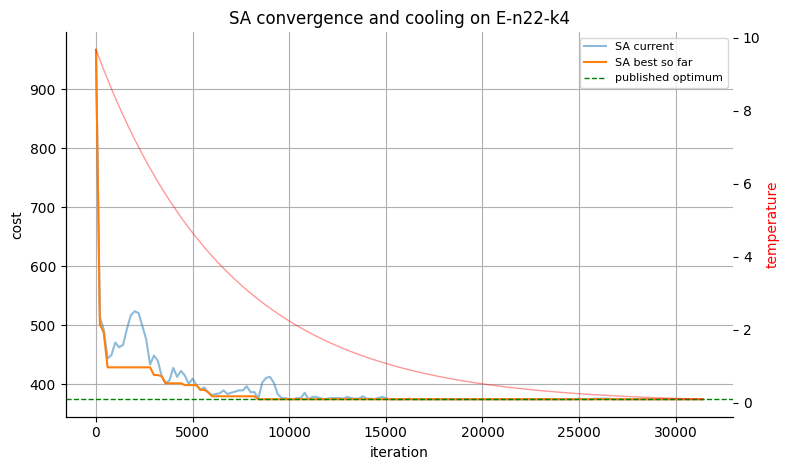

In [26]:
conv = run_sa(tune_inst, iters, seed=7, **SA_PARAMS)["history"]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(conv["iter"], conv["current"], alpha=.5, label="SA current")
ax.plot(conv["iter"], conv["best"], label="SA best so far")
if tune_inst["known_opt"]:
    ax.axhline(tune_inst["known_opt"], color="g", ls="--", lw=1, label="published optimum")
ax2 = ax.twinx()                                           # temperature on the right axis
ax2.plot(conv["iter"], conv["T"], "r", alpha=.4, lw=1)
ax2.set_ylabel("temperature", color="r")
ax2.grid(False)
ax.set_xlabel("iteration")
ax.set_ylabel("cost")
ax.legend(fontsize=8)
ax.set_title(f"SA convergence and cooling on {tune_inst['name']}")
plt.tight_layout()
plt.savefig(FIG / "5_6_convergence.png", dpi=150)
plt.show()

# Comparison
**Fairness rules**
1. Both methods read the same instance.
2. SA gets a fixed iteration budget per instance (`sa_iters_per_n × n`), the same for every seed.
3. Every solution is re-checked by `check_solution`.
4. The **reference** for the gap is the published optimum when there is one. Otherwise it is the best cost found in this study, and the table says so.
5. SA runs with several seeds. We report best, mean and standard deviation, never one lucky run.

## Experiment runner
Every result is one row of `results/runs.csv`. All tables and figures below come from that file.

In [27]:
rows = []

# ILP results (already computed above)
for _, e in exact_df.iterrows():
    rows.append(dict(instance=e["instance"], source=e["source"], n=e["n"], method="ILP", seed=0, cost=e["objective"],
                     runtime_s=e["runtime_s"], feasible=e["feasible"], vehicles=len(e["routes"]) if e["routes"] else 0,
                     status=e["status"], best_bound=e["best_bound"], mip_gap_pct=e["gap_%"], known_opt=e["known_opt"]))

# SA: every instance, every seed
for inst in instances:
    for seed in range(CONFIG["n_seeds"]):
        r = run_sa(inst, sa_budget(inst), seed=seed, **SA_PARAMS)
        chk = check_solution(r["routes"], inst)            # re-check and recompute the cost
        rows.append(dict(instance=inst["name"], source=inst["source"], n=inst["n"], method="SA", seed=seed,
                         cost=chk["cost"], runtime_s=r["runtime_s"], feasible=chk["feasible"],
                         vehicles=chk["vehicles"], status="", known_opt=inst["known_opt"]))
    print(f"  {inst['name']}: {CONFIG['n_seeds']} SA runs done")

runs_df = pd.DataFrame(rows)

# Reference for the gap: the published optimum if known, else the best feasible cost found in this study
best_found = runs_df[runs_df.feasible].groupby("instance")["cost"].min()
runs_df["reference"] = runs_df.apply(lambda r: r.known_opt if pd.notna(r.known_opt) else best_found.get(r.instance, np.nan), axis=1)
runs_df["ref_type"] = np.where(runs_df.known_opt.notna(), "published optimum", "best found in study")
runs_df["gap_pct"] = 100 * (runs_df.cost - runs_df.reference) / runs_df.reference

runs_df.to_csv("results/runs.csv", index=False)
print(len(runs_df), "runs saved to results/runs.csv")
runs_df.head()

  P-n16-k8: 10 SA runs done
  E-n22-k4: 10 SA runs done
  A-n32-k5: 10 SA runs done
  A-n33-k5: 10 SA runs done
  A-n60-k9: 10 SA runs done
  A-n80-k10: 10 SA runs done
  AMZ-c6a02b-n10: 10 SA runs done
  AMZ-c6a02b-n15: 10 SA runs done
  AMZ-c6a02b-n20: 10 SA runs done
  AMZ-c6a02b-n30: 10 SA runs done
  AMZ-c6a02b-n50: 10 SA runs done
  AMZ-c6a02b-n80: 10 SA runs done
128 runs saved to results/runs.csv


,instance,source,n,method,seed,cost,runtime_s,feasible,vehicles,status,best_bound,mip_gap_pct,known_opt,reference,ref_type,gap_pct
0,P-n16-k8,CVRPLIB,15,ILP,0,450.0,1.12,True,8,ProvenOptimal,450.0,0.00,450.0,450.0,published optimum,-2.526374e-14
1,E-n22-k4,CVRPLIB,21,ILP,0,375.0,120.01,True,4,TimeLimit,354.0,5.60,375.0,375.0,published optimum,-1.515825e-14
2,A-n32-k5,CVRPLIB,31,ILP,0,842.0,120.01,True,5,TimeLimit,613.0,27.20,784.0,784.0,published optimum,7.397959e+00
3,A-n33-k5,CVRPLIB,32,ILP,0,725.0,120.01,True,5,TimeLimit,508.0,29.93,661.0,661.0,published optimum,9.682300e+00
4,AMZ-c6a02b-n10,Amazon,10,ILP,0,7177.0,0.05,True,2,ProvenOptimal,7177.0,0.00,NaN,7177.0,best found in study,0.000000e+00


## Solution quality table

One row per instance. It shows the ILP result, the SA best, mean and standard deviation over 10 seeds, and the gap to the reference.

In [28]:
# SA: best, mean, std and mean gap over the seeds, per instance
sa_runs = runs_df[runs_df.method == "SA"]
sa_agg = sa_runs.groupby(["instance", "n"]).agg(best=("cost", "min"), mean=("cost", "mean"), std=("cost", "std"),
                                                 mean_gap_pct=("gap_pct", "mean")).round(2).reset_index()
ilp = runs_df[runs_df.method == "ILP"].set_index("instance")

# One table row per instance
quality = []
for _, g in sa_agg.iterrows():
    ref = runs_df[runs_df.instance == g["instance"]].iloc[0]       # the reference is the same on every row of an instance
    row = {"instance": g["instance"], "n": g["n"], "reference": round(ref.reference, 1), "ref_type": ref.ref_type}
    if g["instance"] in ilp.index:                                 # the ILP was not run on the largest instances
        e = ilp.loc[g["instance"]]
        row |= {"ILP cost": e.cost, "ILP status": e.status, "ILP gap %": e.mip_gap_pct}
    row |= {"SA best": g["best"], "SA mean": g["mean"], "SA std": g["std"], "SA gap %": g["mean_gap_pct"]}
    quality.append(row)

quality_df = pd.DataFrame(quality).sort_values("n").reset_index(drop=True)
quality_df.to_csv("results/quality_table.csv", index=False)
quality_df

,instance,n,reference,ref_type,ILP cost,ILP status,ILP gap %,SA best,SA mean,SA std,SA gap %
0,AMZ-c6a02b-n10,10,7177.0,best found in study,7177.0,ProvenOptimal,0.00,7177.0,7177.0,0.00,0.00
1,AMZ-c6a02b-n15,15,7545.0,best found in study,7545.0,ProvenOptimal,0.00,7545.0,7545.0,0.00,0.00
2,P-n16-k8,15,450.0,published optimum,450.0,ProvenOptimal,0.00,450.0,450.0,0.00,0.00
3,AMZ-c6a02b-n20,20,10733.0,best found in study,10733.0,ProvenOptimal,0.01,10733.0,10739.8,16.30,0.06
4,E-n22-k4,21,375.0,published optimum,375.0,TimeLimit,5.60,375.0,377.1,3.38,0.56
5,AMZ-c6a02b-n30,30,14290.0,best found in study,14290.0,TimeLimit,0.94,14293.0,14380.5,80.06,0.63
6,A-n32-k5,31,784.0,published optimum,842.0,TimeLimit,27.20,784.0,799.9,20.30,2.03
7,A-n33-k5,32,661.0,published optimum,725.0,TimeLimit,29.93,661.0,664.0,5.10,0.45
8,AMZ-c6a02b-n50,50,22190.0,best found in study,NaN,NaN,NaN,22190.0,22722.6,257.63,2.40
9,A-n60-k9,59,1354.0,published optimum,NaN,NaN,NaN,1377.0,1401.4,27.30,3.50


## Runtime against problem size
The ILP is fast and certain on small instances, then hits the time limit. SA stays cheap. Log scale on the y axis.

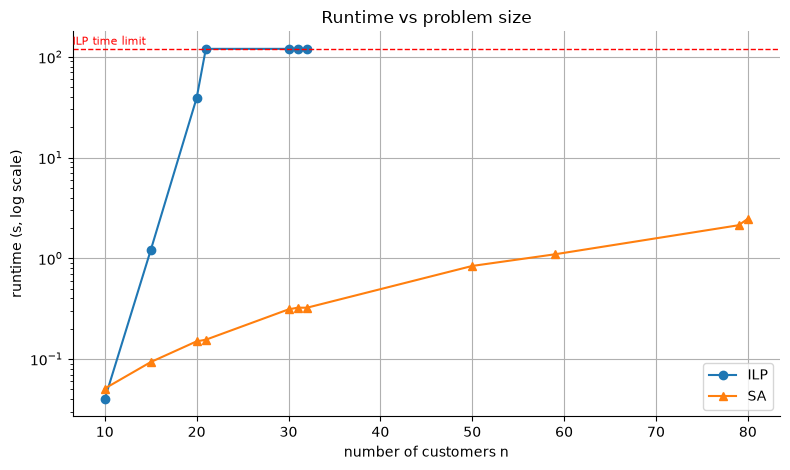

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for method, style in [("ILP", "o-"), ("SA", "^-")]:
    t = runs_df[runs_df.method == method].groupby("n")["runtime_s"].mean()
    ax.semilogy(t.index, t.values, style, label=method)
ax.axhline(CONFIG["exact_time_limit"], color="r", ls="--", lw=1)
ax.text(ax.get_xlim()[0], CONFIG["exact_time_limit"] * 1.1, "ILP time limit", color="r", fontsize=8)
ax.set_xlabel("number of customers n")
ax.set_ylabel("runtime (s, log scale)")
ax.set_title("Runtime vs problem size")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "6_3_runtime_vs_n.png", dpi=150)
plt.show()

## Quality gap against problem size
Gap to the reference (the published optimum when available). Error bars are the standard deviation over seeds. The ILP is shown where it found a solution.

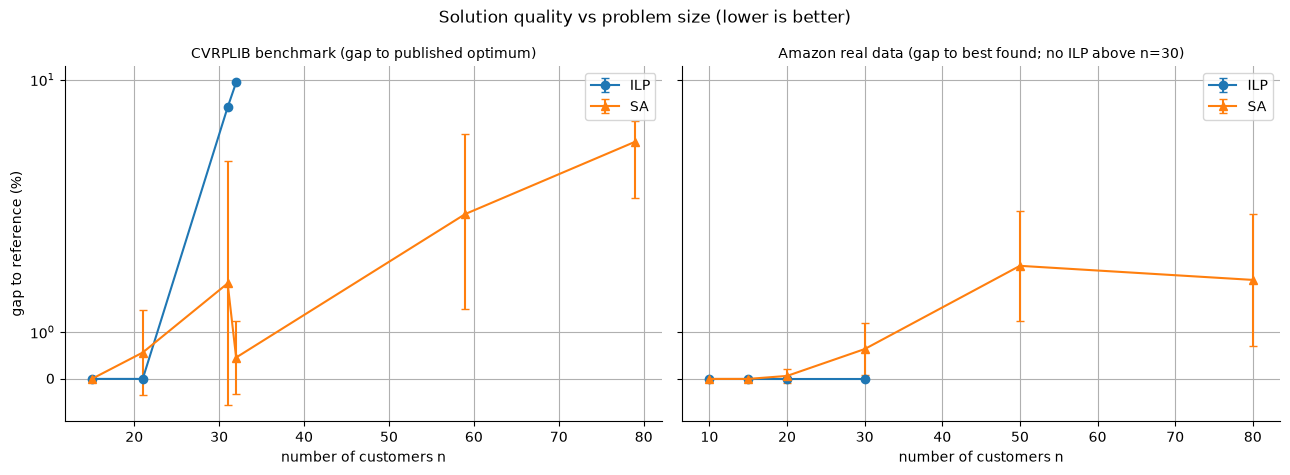

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
panels = [(axs[0], "CVRPLIB", "CVRPLIB benchmark (gap to published optimum)"),
          (axs[1], "Amazon", "Amazon real data (gap to best found; no ILP above n=30)")]
for ax, source, title in panels:
    for method, style in [("ILP", "o"), ("SA", "^")]:
        g = runs_df[(runs_df.source == source) & (runs_df.method == method)].groupby("n")["gap_pct"].agg(["mean", "std"]).fillna(0)
        ax.errorbar(g.index, g["mean"], yerr=g["std"], fmt=style + "-", capsize=3, label=method)
    ax.set_xlabel("number of customers n")
    ax.set_yscale("symlog", linthresh=5)
    ax.set_title(title, fontsize=10)
    ax.legend()
axs[0].set_ylabel("gap to reference (%)")
fig.suptitle("Solution quality vs problem size (lower is better)")
plt.tight_layout()
plt.savefig(FIG / "6_4_gap_vs_n.png", dpi=150)
plt.show()

## Spread across seeds
One box per instance: how much SA's gap changes from seed to seed.

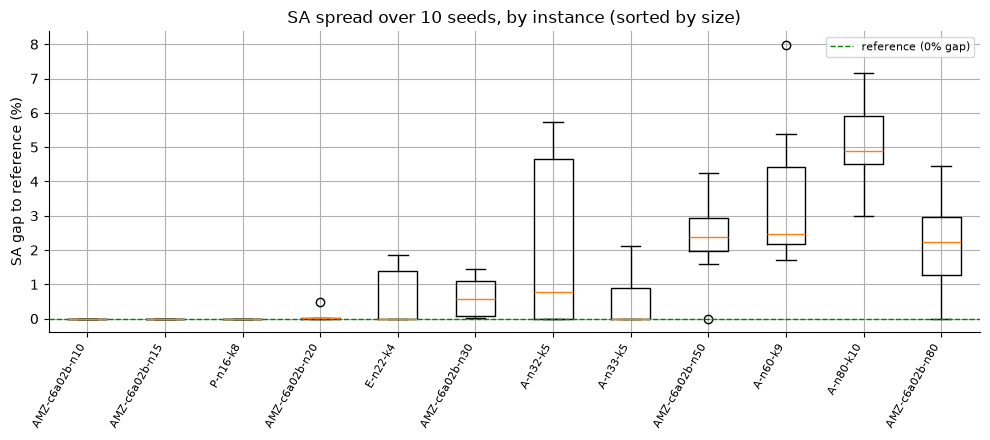

In [27]:
sa = runs_df[runs_df.method == "SA"].sort_values("n")
order = list(dict.fromkeys(sa.instance))                   # instances sorted by size

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([sa[sa.instance == name].gap_pct for name in order])
ax.set_xticklabels(order, rotation=60, ha="right", fontsize=8)
ax.axhline(0, color="g", ls="--", lw=1, label="reference (0% gap)")
ax.set_ylabel("SA gap to reference (%)")
ax.set_title(f"SA spread over {CONFIG['n_seeds']} seeds, by instance (sorted by size)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "6_5_seed_spread.png", dpi=150)
plt.show()

## The same instance solved two ways

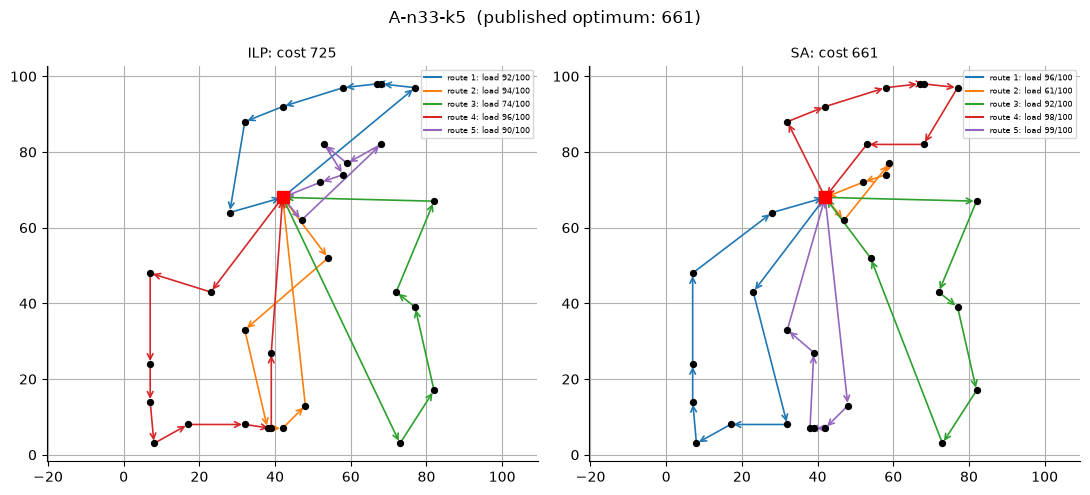

In [28]:
solved = exact_df[exact_df.routes.notna()].set_index("instance")             # instances where the ILP found routes
pick_name = max(solved.index, key=lambda name: by_name[name]["n"])           # the biggest one
inst_p = by_name[pick_name]
ilp_routes = solved.loc[pick_name, "routes"]
best_sa = min((run_sa(inst_p, sa_budget(inst_p), seed=s, **SA_PARAMS) for s in range(3)), key=lambda r: r["cost"])

fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, routes) in zip(axs, [("ILP", ilp_routes), ("SA", best_sa["routes"])]):
    plot_routes(routes, inst_p, ax, f"{name}: cost {check_solution(routes, inst_p)['cost']:.0f}")
fig.suptitle(f"{pick_name}  (published optimum: {inst_p['known_opt']})")
plt.tight_layout()
plt.savefig(FIG / "6_6_side_by_side.png", dpi=150)
plt.show()

## Summary by size band
One row per size band: does the ILP still prove optimality, how good is SA, and what does each cost in time?

In [29]:
runs_df["band"] = pd.cut(runs_df.n, [0, 15, 30, 50, 1000], labels=["n <= 15", "16-30", "31-50", "> 50"])

def band_summary(g):
    ilp, sa = g[g.method == "ILP"], g[g.method == "SA"]
    return pd.Series({
        "ILP attempted": len(ilp),
        "ILP proven optimal": int((ilp.status == "ProvenOptimal").sum()),
        "ILP mean gap %": round(ilp.mip_gap_pct.mean(), 1) if len(ilp) else np.nan,
        "SA mean gap %": round(sa.gap_pct.mean(), 2),
        "SA feasible %": round(100 * sa.feasible.mean(), 0),
        "SA runtime s": round(sa.runtime_s.mean(), 1),
    })

summary = runs_df.groupby("band", observed=True).apply(band_summary)
summary.to_csv("results/summary_by_band.csv")
summary

,ILP attempted,ILP proven optimal,ILP mean gap %,SA mean gap %,SA feasible %,SA runtime s
band,,,,,,
n <= 15,3.0,3.0,0.0,0.00,100.0,0.1
16-30,3.0,1.0,2.4,0.42,100.0,0.2
31-50,2.0,0.0,28.7,1.63,100.0,0.5
> 50,0.0,0.0,NaN,3.56,100.0,1.9


**How to read it**
- Where the ILP is *proven optimal*, it is the ground truth, so SA's gap is exact.
- Where the ILP hits the time limit, the true optimum lies between its best bound and its objective.
- SA has no guarantee, but it stays feasible and fast. Look at the gap and at the spread over seeds.

# Real-world case and demo

## Amazon last-mile instances
Costs here are **seconds of driving time** (asymmetric, from real data), so we report minutes.

In [30]:
amazon_runs = runs_df[runs_df.source == "Amazon"]
amazon_table = amazon_runs.groupby(["instance", "n", "method"]).agg(
    best_min=("cost", lambda s: s.min() / 60), mean_min=("cost", lambda s: s.mean() / 60),
    runtime_s=("runtime_s", "mean")).round(2).reset_index()
amazon_table

,instance,n,method,best_min,mean_min,runtime_s
0,AMZ-c6a02b-n10,10,ILP,119.62,119.62,0.04
1,AMZ-c6a02b-n10,10,SA,119.62,119.62,0.05
2,AMZ-c6a02b-n15,15,ILP,125.75,125.75,1.02
3,AMZ-c6a02b-n15,15,SA,125.75,125.75,0.09
4,AMZ-c6a02b-n20,20,ILP,178.88,178.88,38.78
5,AMZ-c6a02b-n20,20,SA,178.88,179.00,0.15
6,AMZ-c6a02b-n30,30,ILP,238.17,238.17,120.01
7,AMZ-c6a02b-n30,30,SA,238.22,239.68,0.30
8,AMZ-c6a02b-n50,50,SA,369.83,378.71,0.82
9,AMZ-c6a02b-n80,80,SA,543.98,555.41,2.44


## Compare with a simple baseline
The real driver served **all stops with one van**. To compare, we solve the **same stops as a single-vehicle problem** (`K = 1`, capacity unlimited), which is the Travelling Salesman Problem (TSP). The baseline is the **nearest neighbour** rule: always drive to the closest unvisited stop. The driver's own route is not used.
Our model has no time windows, parking or service times, so any saving is an **upper bound on what is really possible**, not a claim that the driver did badly.

In [31]:
def tsp_version(inst):
    """The same stops with one vehicle (TSP). Capacity = total demand, so it never binds.
    (A huge capacity like 10**9 breaks the MTZ constraints numerically.)"""
    return {**inst, "capacity": int(sum(inst["demand"])), "vehicles": 1, "known_opt": None, "name": inst["name"] + "-TSP"}


def nearest_neighbour(D):
    """Baseline: from the depot, always drive to the closest unvisited stop. Returns the visiting order."""
    left, cur, order = set(range(1, len(D))), 0, []
    while left:
        cur = min(left, key=lambda j: D[cur][j])
        order.append(cur)
        left.remove(cur)
    return order


rows = []
for inst in [i for i in instances if i["source"] == "Amazon"]:
    T = tsp_version(inst)
    D = np.asarray(T["dist"])
    base = route_cost(nearest_neighbour(D), D)
    sa_best = min((run_sa(T, sa_budget(T), seed=s, **SA_PARAMS) for s in range(3)), key=lambda r: r["cost"])
    row = {"instance": inst["name"], "baseline": "nearest neighbour", "baseline (min)": base / 60, "SA (min)": sa_best["cost"] / 60}
    if inst["n"] <= CONFIG["exact_max_n"] // 2:                  # the ILP only on the smaller ones
        e = get_exact(T)
        ok = check_solution(e["routes"], T)["feasible"] if e["routes"] else False    # never trust a solver answer without the checker
        row |= {"ILP (min)": e["objective"] / 60, "ILP status": e["status"], "ILP feasible": ok}
    row["saving vs baseline %"] = 100 * (base - sa_best["cost"]) / base
    rows.append(row)

baseline_df = pd.DataFrame(rows).round(2)
baseline_df

,instance,baseline,baseline (min),SA (min),ILP (min),ILP status,ILP feasible,saving vs baseline %
0,AMZ-c6a02b-n10,nearest neighbour,72.13,70.22,70.22,ProvenOptimal,True,2.66
1,AMZ-c6a02b-n15,nearest neighbour,80.30,75.73,75.73,ProvenOptimal,True,5.69
2,AMZ-c6a02b-n20,nearest neighbour,82.55,77.73,77.73,ProvenOptimal,True,5.83
3,AMZ-c6a02b-n30,nearest neighbour,92.82,86.57,NaN,NaN,NaN,6.73
4,AMZ-c6a02b-n50,nearest neighbour,116.72,109.30,NaN,NaN,NaN,6.35
5,AMZ-c6a02b-n80,nearest neighbour,133.90,128.82,NaN,NaN,NaN,3.80


## Demo
One call solves any instance with either method and draws it. Use this in the video.

P-n16-k8 | SA | cost 450 distance units | 8 vehicles | feasible: True | 0.09s | accept rate 0.18
  route 1: 0 -> 1 -> 0   (load 19/35)
  route 2: 0 -> 3 -> 9 -> 5 -> 0   (load 35/35)
  route 3: 0 -> 13 -> 8 -> 0   (load 34/35)
  route 4: 0 -> 14 -> 7 -> 0   (load 34/35)
  route 5: 0 -> 6 -> 0   (load 31/35)
  route 6: 0 -> 2 -> 0   (load 30/35)
  route 7: 0 -> 15 -> 12 -> 10 -> 0   (load 33/35)
  route 8: 0 -> 4 -> 11 -> 0   (load 30/35)


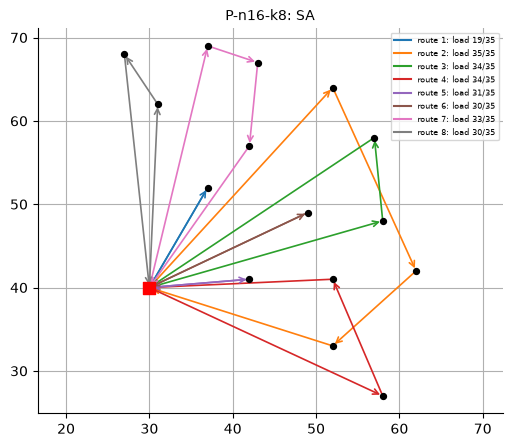

In [32]:
def solve_and_report(name, method="SA", seed=0, time_limit=None):
    """Solve one instance with 'SA' or 'ILP', check the answer, print the routes and draw them."""
    inst = by_name[name]
    if method == "ILP":
        r = solve_exact(inst, time_limit)
        routes, extra = r["routes"], f"{r['status']}, gap {r['gap_%']}%"
    else:
        r = run_sa(inst, sa_budget(inst), seed=seed, **SA_PARAMS)
        routes, extra = r["routes"], f"accept rate {r['accept_rate']:.2f}"
    chk = check_solution(routes, inst)
    print(f"{name} | {method} | cost {chk['cost']:.0f} {inst['cost_unit']} | {chk['vehicles']} vehicles | "
          f"feasible: {chk['feasible']} | {r['runtime_s']:.2f}s | {extra}")
    for k, route in enumerate(routes, 1):
        load = sum(inst["demand"][c] for c in route)
        print(f"  route {k}: 0 -> " + " -> ".join(map(str, route)) + f" -> 0   (load {load}/{inst['capacity']})")
    plt.figure(figsize=(6, 5))
    plot_routes(routes, inst, title=f"{name}: {method}")
    plt.show()


solve_and_report(SMOKE["name"], "SA")